In [1]:
import numpy as np
from itertools import product

import zarr

import tifffile

import scanpy as sc
import squidpy as sq

import dgl

import torch


import matplotlib.pyplot as plt

/nfs/team361/dj16/pypoetry/virtualenvs/model-_goj29qN-py3.12/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/team361/dj16/pypoetry/virtualenvs/model-_goj29qN-py3.12/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [2]:
spatial_file = "/nfs/team361/dj16/data/Xenium_Prime_Ovarian_Cancer_FFPE_XRrun/spatial_preprocessed_ovarian_cancer.h5"

anndata = sc.read_h5ad(spatial_file)

y_start = 10000
x_start = 15000
fov_size = 256

# 1-1. spatial embedding (cells inside this FOV)
points = anndata.obsm["spatial"]

mask = (
    (x_start <= points[:, 0])
    & (points[:, 0] < x_start + fov_size)
    & (y_start <= points[:, 1])
    & (points[:, 1] < y_start + fov_size)
)


# 1-2. image embedding
image_file = "/nfs/team361/dj16/data/Xenium_Prime_Ovarian_Cancer_FFPE_XRrun/image.zarr"

image_array = zarr.open(image_file, mode="r")


fov_image = image_array[
            y_start : y_start + fov_size, 
            x_start : x_start + fov_size, 
            :
            ]

In [3]:
sq.gr.spatial_neighbors(anndata, n_neighs=10, coord_type="generic")

/nfs/team361/dj16/pypoetry/virtualenvs/model-_goj29qN-py3.12/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


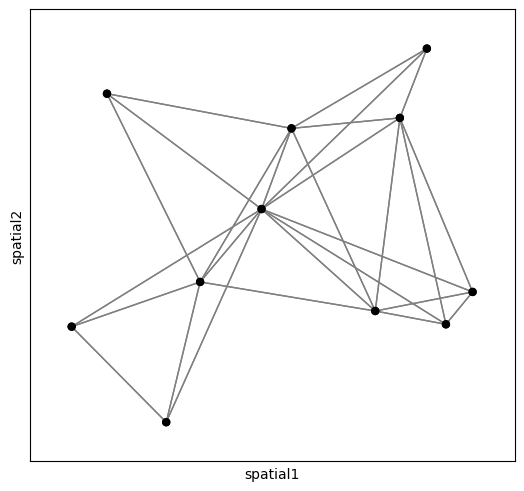

In [4]:
_, idx = anndata.obsp["spatial_connectivities"][420, :].nonzero()
idx = np.append(idx, 420)
sq.pl.spatial_scatter(
    anndata[idx, :],
    shape=None,
    # color="cell type",
    connectivity_key="spatial_connectivities",
    size=100,
)

/nfs/team361/dj16/pypoetry/virtualenvs/model-_goj29qN-py3.12/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


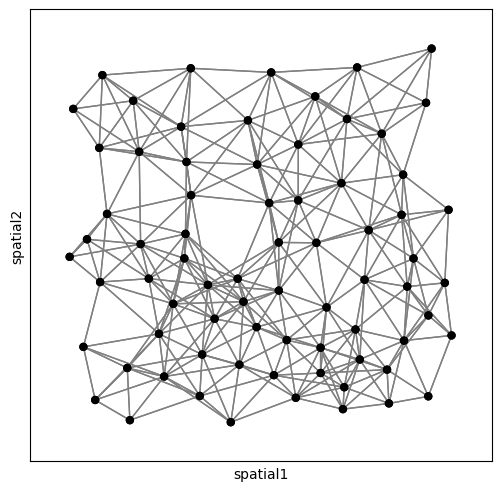

In [5]:
# Scatter plot with spatial coordinate of cells
sq.pl.spatial_scatter(
    anndata[mask,:],
    shape=None,
    # color="cell type",
    connectivity_key="spatial_connectivities",
    size=100,
)

In [6]:
sparse_maxtrix = anndata[mask,:].obsp["spatial_connectivities"]

graph = dgl.from_scipy(sparse_maxtrix)

node_features = torch.Tensor(anndata[mask,:].X.toarray())
graph.ndata['feat'] = node_features

graph.edata['edge_weight'] = torch.ones(len(graph.edges()[0]))

graph.edata['edge_mask'] = torch.ones(len(graph.edges()[0]))

In [7]:
grid_size = fov_size // 2**2

subgraphs = []

for x_start_grid, y_start_grid in product(range(0, fov_size, grid_size), range(0, fov_size, grid_size)):
    
    mask_grid = (
        (x_start + x_start_grid <= points[:, 0])
        & (points[:, 0] < x_start + x_start_grid + grid_size)
        & (y_start + y_start_grid <= points[:, 1])
        & (points[:, 1] < y_start + y_start_grid + grid_size)
    )

    sparse_maxtrix_grid = anndata[mask_grid,:].obsp["spatial_connectivities"]

    subgraph_grid = dgl.from_scipy(sparse_maxtrix_grid)

    node_features_grid = torch.Tensor(anndata[mask_grid,:].X.toarray())
    subgraph_grid.ndata['feat'] = node_features_grid
    
    subgraphs.append(subgraph_grid)

In [8]:
subgraphs

[Graph(num_nodes=3, num_edges=6,
       ndata_schemes={'feat': Scheme(shape=(5101,), dtype=torch.float32)}
       edata_schemes={}),
 Graph(num_nodes=3, num_edges=6,
       ndata_schemes={'feat': Scheme(shape=(5101,), dtype=torch.float32)}
       edata_schemes={}),
 Graph(num_nodes=5, num_edges=18,
       ndata_schemes={'feat': Scheme(shape=(5101,), dtype=torch.float32)}
       edata_schemes={}),
 Graph(num_nodes=6, num_edges=24,
       ndata_schemes={'feat': Scheme(shape=(5101,), dtype=torch.float32)}
       edata_schemes={}),
 Graph(num_nodes=3, num_edges=6,
       ndata_schemes={'feat': Scheme(shape=(5101,), dtype=torch.float32)}
       edata_schemes={}),
 Graph(num_nodes=3, num_edges=6,
       ndata_schemes={'feat': Scheme(shape=(5101,), dtype=torch.float32)}
       edata_schemes={}),
 Graph(num_nodes=7, num_edges=38,
       ndata_schemes={'feat': Scheme(shape=(5101,), dtype=torch.float32)}
       edata_schemes={}),
 Graph(num_nodes=5, num_edges=16,
       ndata_schemes={'feat': Sc

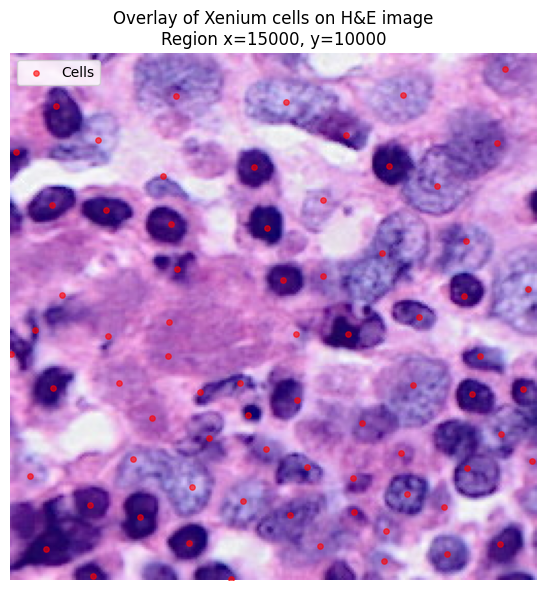

In [9]:
# 1. FOV 안의 세포 위치만 추출 (FOV 기준으로 좌표를 조정)
subset_points = points[mask]
adjusted_points = subset_points - np.array([x_start, y_start])

# 2. 이미지와 포인트 함께 시각화
plt.figure(figsize=(6, 6))
plt.imshow(fov_image, origin="upper")  # 또는 origin="lower", 이미지 방향에 따라 확인 필요
plt.scatter(
    adjusted_points[:, 0], 
    adjusted_points[:, 1], 
    s=15, 
    c="red", 
    alpha=0.6, 
    label="Cells"
)
plt.title(f"Overlay of Xenium cells on H&E image\nRegion x={x_start}, y={y_start}")
plt.axis("off")
plt.legend()
plt.tight_layout()
plt.show()


/tmp/ipykernel_1034990/625481897.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


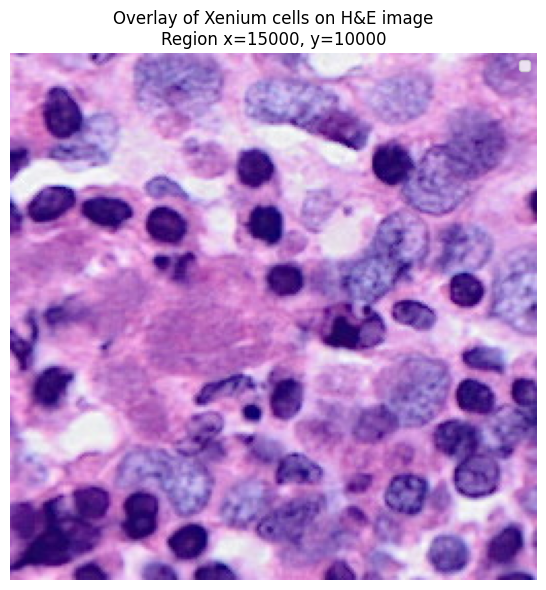

In [10]:
# 1. FOV 안의 세포 위치만 추출 (FOV 기준으로 좌표를 조정)
subset_points = points[mask]
adjusted_points = subset_points - np.array([x_start, y_start])

# 2. 이미지와 포인트 함께 시각화
plt.figure(figsize=(6, 6))
plt.imshow(fov_image, origin="upper")  # 또는 origin="lower", 이미지 방향에 따라 확인 필요

plt.title(f"Overlay of Xenium cells on H&E image\nRegion x={x_start}, y={y_start}")
plt.axis("off")
plt.legend()
plt.tight_layout()
plt.show()
